# Phát hiện và phân loại rác thải bằng YOLOv8n (chạy trên Google Colab)

**Notebook này làm gì?** Dạy máy tính **nhìn ảnh và tìm ra rác**: khoanh khung quanh từng món rác, nói đó là **loại rác nào** (9 loại) và **chắc chắn bao nhiêu phần trăm**.

**Trước khi bấm chạy, cần chuẩn bị 3 việc:**
1. **Bật GPU:** menu *Runtime → Change runtime type → T4 GPU* (không có GPU thì rất chậm).
2. **Đưa file dữ liệu lên Google Drive:** file `asian-waste-detection-challenge.zip` để ở ngoài cùng của *My Drive*.
3. **Chạy lần lượt từng ô từ trên xuống dưới** (bấm nút ▶ hoặc nhấn `Shift + Enter`), ô trước xong mới chạy ô sau.

**Các bước trong notebook:**

| Bước | Việc làm | Giải thích đơn giản |
|---|---|---|
| 1 | Cài thư viện, kiểm tra GPU | Chuẩn bị "đồ nghề" |
| 2 | Kết nối Kaggle | *(Đã bỏ qua vì đã tải dữ liệu bằng tay)* |
| 3 | Lấy file ZIP từ Drive | Mang dữ liệu vào Colab |
| 4 | Giải nén và đếm ảnh | Mở gói dữ liệu ra, kiểm tra đủ ảnh chưa |
| 5–8 | Đọc và sửa file cấu hình `.yaml` | Chỉ cho YOLO biết ảnh nằm ở đâu, có những loại rác nào |
| 9 | **Huấn luyện** (train) | Cho máy học |
| 10–11 | Chấm điểm trên tập valid và test | Kiểm tra máy học giỏi đến đâu |
| 12 | Thử với một ảnh bất kỳ | Xem kết quả thật |
| Cuối | Lưu kết quả | Tránh mất khi Colab tắt |

**Vài từ cần biết:**
- **YOLO** (You Only Look Once): mô hình "nhìn một lần là tìm ra mọi vật trong ảnh".
- **Epoch**: một lượt cho máy học hết toàn bộ ảnh train. 20 epoch = học 20 lượt.
- **Train / Valid / Test**: tập ảnh để học / để theo dõi lúc học / để chấm điểm cuối.
- **Precision, Recall, mAP**: các điểm số từ 0 đến 1, **càng cao càng tốt** (giải thích kỹ hơn ở bước 10).

**BƯỚC 1: CÀI THƯ VIỆN VÀ KIỂM TRA GPU**

Thư viện giống như "hộp đồ nghề" có sẵn công cụ, mình không phải tự viết lại từ đầu:
* `ultralytics`: chứa mô hình **YOLO** cùng các lệnh để huấn luyện, dự đoán và chấm điểm.
* `kaggle`: dùng để tải dữ liệu từ trang Kaggle.
* `pyyaml`: đọc các file cấu hình đuôi `.yaml`.

Ô code bên dưới cũng kiểm tra xem Colab có **GPU** không. Kết quả mong muốn: `CUDA available: True` và tên GPU (ví dụ Tesla T4).

In [9]:
# ===== BƯỚC 1: cài thư viện và kiểm tra GPU =====

# Cài 3 thư viện cần dùng. Dấu ! nghĩa là chạy lệnh của máy (không phải lệnh Python).
# -q: cài "im lặng" cho đỡ rối màn hình.  -U: lấy bản mới nhất.
!pip -q install -U ultralytics kaggle pyyaml

# "Mở hộp đồ nghề": nạp các thư viện để dùng bên dưới.
import os                      # làm việc với hệ điều hành (biến môi trường, thư mục)
import glob                    # tìm file theo mẫu tên
import zipfile                 # đọc và giải nén file .zip
import shutil                  # sao chép, di chuyển file
from pathlib import Path       # viết đường dẫn thư mục cho gọn

import yaml                    # đọc file cấu hình .yaml
import torch                   # PyTorch: thư viện tính toán của mạng nơ-ron
from ultralytics import YOLO   # mô hình YOLO phát hiện vật thể

# Kiểm tra máy có GPU không. GPU giúp huấn luyện nhanh hơn CPU rất nhiều.
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())      # True = có GPU dùng được
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))          # in tên GPU (ví dụ Tesla T4)
else:
    # Cách bật GPU: menu Runtime > Change runtime type > chọn T4 GPU
    print("No GPU detected. Please enable a GPU via Runtime > Change runtime type")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


**BƯỚC 2: KẾT NỐI KAGGLE (đã bỏ qua)**

Bước này dùng để lấy "chìa khóa" (token) từ https://www.kaggle.com/settings/api nhằm tải dữ liệu thẳng từ Kaggle.
**Nhóm đã tải file ZIP bằng tay rồi nên không cần token nữa.** Chạy ô bên dưới nếu báo lỗi cũng không sao.

In [10]:
# ===== BƯỚC 2: kết nối Kaggle (ĐÃ BỎ QUA vì đã tải file ZIP bằng tay) =====
# Ô này thử lấy token Kaggle từ "Secrets" của Colab (biểu tượng chìa khóa bên trái).
# Nếu không có token thì nó chỉ in một dòng thông báo, KHÔNG ảnh hưởng các bước sau.
import os
try:
    from google.colab import userdata
    # Lấy token tên KAGGLE_API_TOKEN rồi cất vào biến môi trường để thư viện kaggle dùng.
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle API has been configured")
except Exception as e:
    # Không có token thì bỏ qua, không dừng chương trình.
    print("Bo qua Kaggle API (khong can khi da co file ZIP):", type(e).__name__)

Kaggle API has been configured


**BƯỚC 3: LẤY FILE DỮ LIỆU (ZIP) TỪ GOOGLE DRIVE**

Colab là máy tính tạm thời, tắt đi là mất hết. Vì vậy mình để file ZIP ở Google Drive, rồi chép vào Colab mỗi lần chạy.
Nhớ đặt file `asian-waste-detection-challenge.zip` ở **ngoài cùng** của *My Drive*. Lần đầu chạy, Colab sẽ hiện hộp thoại xin quyền truy cập Drive: bấm **Cho phép**.

In [11]:
# ===== BƯỚC 3: lấy file ZIP dữ liệu từ Google Drive =====
# TRƯỚC KHI CHẠY: để file asian-waste-detection-challenge.zip ở ngoài cùng của My Drive.

# "Gắn" Google Drive vào Colab để đọc được file trong Drive. Lần đầu sẽ hiện hộp thoại xin quyền.
from google.colab import drive
drive.mount('/content/drive')

# Tạo thư mục tạm để chứa file ZIP (đã có rồi thì thôi, không báo lỗi).
DOWNLOAD_DIR = Path("/content/kaggle_download")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Tên file ZIP trong Drive. Nếu bạn đặt tên khác thì sửa lại dòng này cho đúng.
ZIP_NAME = "asian-waste-detection-challenge.zip"

# Chép file ZIP từ Drive sang Colab. Colab tự thay {ZIP_NAME} và {DOWNLOAD_DIR} bằng giá trị của biến.
!cp "/content/drive/MyDrive/{ZIP_NAME}" "{DOWNLOAD_DIR}/"

# Tìm các file .zip vừa chép. Nếu không thấy file nào thì dừng và báo lỗi rõ ràng.
zip_files = list(DOWNLOAD_DIR.glob("*.zip"))
if not zip_files:
    raise FileNotFoundError(
        "Khong thay file ZIP. Kiem tra file da nam ngoai cung trong My Drive chua va ZIP_NAME co dung ten khong."
    )

# In tên và dung lượng file (khoảng 640 MB là đúng).
for f in zip_files:
    print(f"{f.name}: {f.stat().st_size / (1024**2):.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
asian-waste-detection-challenge.zip: 643.3 MB


**BƯỚC 4: GIẢI NÉN DỮ LIỆU**

Mở file ZIP ra thư mục `/content/waste_dataset`. Bên trong sẽ có 3 thư mục `train`, `valid`, `test`, mỗi thư mục lại có `images` (ảnh) và `labels` (nhãn: vị trí và loại rác của từng ảnh).

In [12]:
# ===== BƯỚC 4: giải nén dữ liệu =====
import zipfile

# Thư mục sẽ chứa dữ liệu sau khi giải nén.
DATASET_DIR = Path("/content/waste_dataset")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Giải nén từng file ZIP tìm được ở bước 3.
for zip_path in zip_files:
    print("Extracting:", zip_path.name)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATASET_DIR)     # "giải nén tất cả" vào thư mục đích

print("Dataset has been extracted to:", DATASET_DIR)

Extracting: asian-waste-detection-challenge.zip
Dataset has been extracted to: /content/waste_dataset


In [13]:
# Gắn Google Drive một lần nữa. Ô này LẶP LẠI với bước 3 (Drive đã gắn rồi), chạy hay bỏ đều không sao.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**BƯỚC 4.1: ĐẾM ẢNH ĐỂ KIỂM TRA**

Đếm số ảnh trong mỗi thư mục. Kết quả đúng: train 9.964, valid 1.327, test 1.336 ảnh (tổng 12.627). Nếu số khác nhiều nghĩa là giải nén thiếu hoặc nhầm dữ liệu.

In [14]:
# ===== BƯỚC 4.1: đếm số ảnh trong từng thư mục =====

# Các đuôi file được coi là ảnh.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Đếm ảnh ở từng tập: train (để học), valid (để theo dõi), test (để chấm điểm cuối).
for split in ["train", "valid", "test"]:
    split_dir = DATASET_DIR / split          # đường dẫn tới thư mục của tập đó

    if split_dir.exists():
        # rglob("*"): tìm mọi file trong thư mục (kể cả thư mục con); chỉ giữ file có đuôi ảnh.
        images = [
            f for f in split_dir.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ]
        print(f"{split.upper()}: {len(images):,} images")    # dấu , ngăn cách hàng nghìn
    else:
        print(f"{split.upper()}: Folder not found")          # không thấy thư mục

# Đếm tổng số ảnh của cả bộ dữ liệu.
all_images = [
    f for f in DATASET_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
]

print("-" * 35)
print(f"TOTAL: {len(all_images):,} images")       # kết quả đúng: 12,627

TRAIN: 9,964 images
VALID: 1,327 images
TEST: 1,336 images
-----------------------------------
TOTAL: 12,627 images


**BƯỚC 5: XEM BÊN TRONG THƯ MỤC DỮ LIỆU CÓ GÌ**

Ô này liệt kê các file và tìm file cấu hình `.yaml`. Với YOLO, file `.yaml` giống một **tờ hướng dẫn** ghi:
* Đường dẫn tới ảnh train, valid, test.
* Số loại rác (số lớp, ví dụ 9).
* Tên từng loại rác (Plastic, Paper, Metal, Glass...).

*(YAML là viết tắt của "YAML Ain't Markup Language": một kiểu file chữ đơn giản để ghi cấu hình.)*

In [15]:
# ===== BƯỚC 5: xem trong thư mục dữ liệu có gì =====

# Lấy danh sách MỌI file và thư mục con bên trong dữ liệu.
all_items = list(DATASET_DIR.rglob("*"))
print("Tổng số file/thư mục:", f"{len(all_items):,}")

# In thử 60 đường dẫn đầu tiên để biết dữ liệu được sắp xếp thế nào.
# (Lưu ý nhỏ: vì trong code viết hai dấu gạch chéo ngược, màn hình sẽ in nguyên văn ký hiệu \n thay vì xuống dòng. Chỉ là lỗi hiển thị, không ảnh hưởng kết quả.)
print("\\nMột số đường dẫn đầu tiên:")
for p in all_items[:60]:
    print(p.relative_to(DATASET_DIR))       # in đường dẫn tính từ thư mục dữ liệu

# Tìm các file cấu hình .yaml (hoặc .yml).
yaml_files = list(DATASET_DIR.rglob("*.yaml")) + list(DATASET_DIR.rglob("*.yml"))
print("\\nCác file YAML tìm thấy:")
for p in yaml_files:
    print(p.relative_to(DATASET_DIR))

Tổng số file/thư mục: 25,266
\nMột số đường dẫn đầu tiên:
train
valid
test
data.yaml
README.roboflow.txt
README.dataset.txt
train/images
train/labels
valid/images
valid/labels
test/images
test/labels
test/images/285_jpg.rf.2515ed4c437fb251ea19ad26a2f491e6.jpg
test/images/400059_jpg.rf.befe737a194cf15fe7984924d3b77903.jpg
test/images/9_erip_su_11-15_15-07-10_aft_DF5_jpg.rf.a5c2dc9b315fd4bb39a9e6b4bc0eda3b.jpg
test/images/paper580_jpg.rf.318ce67b310e94c7e74b255622e661ce.jpg
test/images/9_dsp_su_11-10_09-32-13_for_DF5_jpg.rf.79afd793652e8ce66f9db51ca587059e.jpg
test/images/1000_jpg.rf.7b3a653386d6a142f73e63a2ea08e7e6.jpg
test/images/metal_2654_jpg.rf.2ebe41786435c831f3a55d1eb6bce692.jpg
test/images/metal_2176_jpg.rf.d581d5db65c811971f2afdb694a61a3d.jpg
test/images/PET-1567_jpg.rf.4e9829635e0b0323ab8ad26b5e8ab7c3.jpg
test/images/82746_jpg.rf.4d40da1bfc1cdf1850574f5cda08d730.jpg
test/images/888_jpg.rf.e3de92eb2581510b5476bba42b879e15.jpg
test/images/00002907_jpg.rf.247525563b65eea075e2b9ad2

**BƯỚC 6: ĐỌC FILE CẤU HÌNH CỦA DỮ LIỆU**

Mở file `.yaml` ra đọc và in nội dung lên màn hình. Kết quả đúng sẽ thấy: `nc: 9` (9 loại) và danh sách tên 9 loại rác.

In [16]:
# ===== BƯỚC 6: đọc file cấu hình .yaml của dữ liệu =====

# Hàm nhỏ: mở một file .yaml và trả về nội dung dưới dạng từ điển Python.
def read_yaml(path):
    with open(path, "r", encoding="utf-8") as f:
        return yaml.safe_load(f)

# Trong các file .yaml tìm được, chọn file "đủ thông tin" cho YOLO:
# phải có train (ảnh học), val (ảnh theo dõi) và names (tên các lớp).
candidate_yaml = []
for yp in yaml_files:
    try:
        cfg = read_yaml(yp)
        if isinstance(cfg, dict) and "train" in cfg and "val" in cfg and "names" in cfg:
            candidate_yaml.append((yp, cfg))
    except Exception as e:
        print("cannot read", yp, ":", e)       # file nào đọc lỗi thì báo rồi bỏ qua

# Không có file nào đủ thông tin thì dừng và báo lỗi.
if not candidate_yaml:
    raise RuntimeError(
        "Không tìm thấy YAML có đủ train, val và names. "
        "Hãy kiểm tra cấu trúc dataset và annotation trước khi tiếp tục."
    )

# Chọn file đầu tiên phù hợp; nếu dataset có nhiều file YAML, xem danh sách ở output phía trên.
DATA_YAML_ORIGINAL, data_cfg = candidate_yaml[0]
print("Chọn file cấu hình:", DATA_YAML_ORIGINAL)
print(yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True))      # in nội dung cho dễ xem

Chọn file cấu hình: /content/waste_dataset/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 9
names:
- Animal Waste
- Construction Waste
- Garbage Bag
- Glass
- Metal
- Organic
- Paper
- Plastic
- waste
roboflow:
  workspace: fyp-loofa
  project: asian-waste-detection-dihfa-m9t9o-hqccl-4ptpz
  version: 8
  license: CC BY 4.0
  url: https://universe.roboflow.com/fyp-loofa/asian-waste-detection-dihfa-m9t9o-hqccl-4ptpz/dataset/8



**BƯỚC 7: SỬA ĐƯỜNG DẪN TRONG FILE CẤU HÌNH**

File `.yaml` gốc ghi đường dẫn dạng tương đối (ví dụ `../train/images`), dễ khiến YOLO **không tìm thấy ảnh**. Bước này tạo một file `.yaml` mới với đường dẫn **đầy đủ** (tuyệt đối).

Có 2 ô: ô đầu là **code cũ đã tắt** (không chạy), ô sau (**"STEP 7 AGAIN"**) là cách làm đơn giản đang dùng thật.

In [17]:
# ĐÂY LÀ CODE CŨ ĐÃ TẮT (mỗi dòng đều bắt đầu bằng dấu #) nên KHÔNG chạy gì cả.
# Giữ lại để tham khảo. Việc "sửa đường dẫn" đang được làm bằng cách đơn giản hơn ở ô ngay bên dưới.
# def resolve_dataset_path(value, yaml_parent, dataset_root):
#     if value is None:
#         return None
#     p = Path(str(value))
#     if p.is_absolute() and p.exists():
#         return str(p)

#     candidates = [
#         yaml_parent / p,
#         dataset_root / p,
#         yaml_parent / p.name,
#         dataset_root / p.name,
#     ]
#     for candidate in candidates:
#         if candidate.exists():
#             return str(candidate.resolve())

#     # Tìm thư mục có cùng tên bên trong dataset.
#     matches = [x for x in dataset_root.rglob(p.name) if x.exists()]
#     if matches:
#         return str(matches[0].resolve())

#     raise FileNotFoundError(
#         f"Không tìm thấy đường dẫn '{value}'. "
#         "Cần kiểm tra lại cấu trúc thư mục và file YAML."
#     )

# fixed_cfg = dict(data_cfg)
# fixed_cfg["path"] = str(DATASET_DIR.resolve())

# for split in ("train", "val", "test"):
#     if split in fixed_cfg and fixed_cfg[split] is not None:
#         fixed_cfg[split] = resolve_dataset_path(
#             fixed_cfg[split], DATA_YAML_ORIGINAL.parent, DATASET_DIR
#         )

# FIXED_YAML = Path("/content/waste_dataset/data_fixed.yaml")
# with open(FIXED_YAML, "w", encoding="utf-8") as f:
#     yaml.safe_dump(fixed_cfg, f, sort_keys=False, allow_unicode=True)

# print("YAML dùng cho YOLO:", FIXED_YAML)
# print(yaml.safe_dump(fixed_cfg, sort_keys=False, allow_unicode=True))

In [18]:
# ===== BƯỚC 7 (làm thật): tạo file cấu hình có đường dẫn ĐẦY ĐỦ =====

# Sao chép nội dung file .yaml đã đọc (để giữ nguyên số lớp, tên lớp...), rồi chỉ sửa các đường dẫn.
fixed_cfg = dict(data_cfg)

# Thư mục gốc của dữ liệu.
fixed_cfg["path"] = str(DATASET_DIR.resolve())

# Ghi đường dẫn đầy đủ tới ảnh train / valid / test (resolve() = đổi thành đường dẫn tuyệt đối).
fixed_cfg["train"] = str((DATASET_DIR / "train" / "images").resolve())
fixed_cfg["val"] = str((DATASET_DIR / "valid" / "images").resolve())
fixed_cfg["test"] = str((DATASET_DIR / "test" / "images").resolve())

# Kiểm tra cả 3 thư mục có thật không; thiếu cái nào thì dừng và báo lỗi ngay.
for split in ("train", "val", "test"):
    if not Path(fixed_cfg[split]).exists():
        raise FileNotFoundError(f"Cannot find {split}: {fixed_cfg[split]}")

# Lưu thành file .yaml mới. Từ giờ YOLO sẽ dùng file này (biến FIXED_YAML).
FIXED_YAML = Path("/content/waste_dataset/data_fixed.yaml")

with open(FIXED_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(fixed_cfg, f, sort_keys=False, allow_unicode=True)

# In nội dung file mới ra để kiểm tra bằng mắt.
print("Corrected dataset configuration:")
print(yaml.safe_dump(fixed_cfg, sort_keys=False, allow_unicode=True))

Corrected dataset configuration:
train: /content/waste_dataset/train/images
val: /content/waste_dataset/valid/images
test: /content/waste_dataset/test/images
nc: 9
names:
- Animal Waste
- Construction Waste
- Garbage Bag
- Glass
- Metal
- Organic
- Paper
- Plastic
- waste
roboflow:
  workspace: fyp-loofa
  project: asian-waste-detection-dihfa-m9t9o-hqccl-4ptpz
  version: 8
  license: CC BY 4.0
  url: https://universe.roboflow.com/fyp-loofa/asian-waste-detection-dihfa-m9t9o-hqccl-4ptpz/dataset/8
path: /content/waste_dataset



**BƯỚC 8: KIỂM TRA LẠI ẢNH VÀ SỐ LỚP**

Đếm lại ảnh theo đường dẫn trong file `.yaml` mới, và in ra số lớp cùng tên các lớp để chắc chắn mọi thứ đúng trước khi huấn luyện.

In [19]:
# ===== BƯỚC 8: kiểm tra lại số ảnh và số lớp theo file cấu hình mới =====

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}     # các đuôi file được coi là ảnh

# Hàm đếm số ảnh. Nhận vào đường dẫn tới thư mục ảnh (hoặc file .txt liệt kê danh sách ảnh).
def count_images(folder):
    folder = Path(folder)
    if folder.is_file() and folder.suffix.lower() == ".txt":
        # Trường hợp YAML trỏ tới file danh sách ảnh: đọc từng dòng, mỗi dòng là một đường dẫn ảnh.
        paths = []
        for line in folder.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if line:
                p = Path(line)
                if not p.is_absolute():
                    p = folder.parent / p
                paths.append(p)
        return sum(p.exists() and p.suffix.lower() in IMAGE_EXTS for p in paths)
    if folder.is_dir():
        # Trường hợp thường gặp: đây là thư mục, đếm các file ảnh bên trong.
        return sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
    return 0

# Đếm ảnh ở từng tập theo đường dẫn trong file cấu hình mới.
for split in ("train", "val", "test"):
    if split in fixed_cfg:
        print(f"{split}: {fixed_cfg[split]} -> {count_images(fixed_cfg[split]):,} ảnh")

# In số lớp (số loại rác) và tên các lớp. Kết quả đúng: 9 lớp.
print("\\nSố class:", len(fixed_cfg["names"]))
print("Tên class:", fixed_cfg["names"])

train: /content/waste_dataset/train/images -> 9,964 ảnh
val: /content/waste_dataset/valid/images -> 1,327 ảnh
test: /content/waste_dataset/test/images -> 1,336 ảnh
\nSố class: 9
Tên class: ['Animal Waste', 'Construction Waste', 'Garbage Bag', 'Glass', 'Metal', 'Organic', 'Paper', 'Plastic', 'waste']


**BƯỚC 9: HUẤN LUYỆN YOLO (cho máy học)**

Đây là bước **quan trọng và lâu nhất** (khoảng 45 phút trên GPU T4). Cách làm:
1. Lấy mô hình `yolov8n.pt` đã được học sẵn trên bộ ảnh lớn COCO (giống người đã học hết lớp 9).
2. Cho mô hình học tiếp trên ảnh rác của mình, **học 20 lượt** (epoch).
3. Mỗi lượt, mô hình tự chấm điểm trên tập valid. Mô hình tốt nhất được lưu thành file `best.pt`.

Đây gọi là **fine-tune** (tinh chỉnh) toàn bộ mô hình. Màn hình sẽ in rất nhiều dòng, cứ để yên cho chạy xong.

In [20]:
# ===== BƯỚC 9: HUẤN LUYỆN YOLO (cho máy học) =====

# --- Các "núm vặn" do mình chọn ---
MODEL_NAME = "yolov8n.pt"   # mô hình xuất phát: bản "nano" (nhỏ, nhanh) đã học sẵn trên bộ ảnh COCO
EPOCHS = 20 #standard 30    # số lượt học hết toàn bộ ảnh train (thường dùng khoảng 30)
IMAGE_SIZE = 640            # ảnh được thu về 640x640 điểm ảnh trước khi đưa vào mô hình
BATCH_SIZE = 16             # mỗi lần đưa 16 ảnh vào học (nhiều quá thì tràn bộ nhớ GPU)

# Nạp mô hình xuất phát.
model = YOLO(MODEL_NAME)

# Chọn thiết bị tính: GPU số 0 nếu có, không có thì dùng CPU (chậm hơn rất nhiều).
train_device = 0 if torch.cuda.is_available() else "cpu"

# Bắt đầu học. Quá trình này mất khoảng 45 phút trên GPU T4 và in rất nhiều dòng.
results = model.train(
    data=str(FIXED_YAML),                   # file cấu hình ở bước 7 (chỉ đường tới ảnh và tên lớp)
    epochs=EPOCHS,                          # học bao nhiêu lượt
    imgsz=IMAGE_SIZE,                       # kích thước ảnh
    batch=BATCH_SIZE,                       # số ảnh mỗi lần
    device=train_device,                    # học bằng GPU hay CPU
    project="/content/waste_yolo_runs",     # thư mục lưu kết quả học
    name="yolov8n_waste_corrected",         # tên lần chạy (thư mục con trong project)
    patience=8,                             # dừng sớm nếu 8 lượt liền không tiến bộ thêm
    plots=True,                             # vẽ các biểu đồ (loss, mAP...) để xem lại
    save=True                               # lưu mô hình (best.pt = tốt nhất, last.pt = lượt cuối)
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/waste_dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_waste_corrected, nbs=64, nms=None, opset=

**BƯỚC 10: CHẤM ĐIỂM TRÊN TẬP VALID**

Dùng mô hình tốt nhất (`best.pt`) để chấm điểm. Các điểm đều nằm từ 0 đến 1, **càng cao càng tốt**:
* **Precision**: trong những khung máy vẽ ra, bao nhiêu phần đúng.
* **Recall**: trong số rác thật có trong ảnh, máy tìm ra được bao nhiêu phần.
* **mAP50**: điểm tổng hợp khi khung dự đoán chồng khớp khung thật từ 50% trở lên.
* **mAP50-95**: điểm khắt khe hơn (khung phải khít hơn nhiều), nên thấp hơn mAP50.

In [21]:
# ===== BƯỚC 10: chấm điểm mô hình tốt nhất trên tập VALID =====

# best.pt là mô hình có điểm tốt nhất trong lúc học. Chưa có file này nghĩa là bước 9 chưa chạy xong.
best_weights = Path("/content/waste_yolo_runs/yolov8n_waste_corrected/weights/best.pt")
if not best_weights.exists():
    raise FileNotFoundError(f"Không tìm thấy best.pt tại {best_weights}")

# Nạp mô hình tốt nhất rồi chấm điểm trên tập valid (val = validation).
best_model = YOLO(str(best_weights))
metrics = best_model.val(data=str(FIXED_YAML), imgsz=IMAGE_SIZE, device=train_device)

# In 4 điểm số (từ 0 đến 1, càng cao càng tốt):
print("Precision (Box):", metrics.box.mp)    # trong các khung máy vẽ, bao nhiêu phần đúng
print("Recall (Box):", metrics.box.mr)       # trong rác thật, máy tìm ra được bao nhiêu phần
print("mAP50:", metrics.box.map50)           # điểm tổng hợp khi khung chồng khớp từ 50%
print("mAP50-95:", metrics.box.map)          # điểm khắt khe hơn: khung phải khít hơn nhiều

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1747.4±850.2 MB/s, size: 39.7 KB)
val: Scanning /content/waste_dataset/valid/labels.cache... 1327 images, 0 backgrounds, 2 corrupt: 100% ━━━━━━━━━━━━ 1327/1327 506.0Mit/s 0.0s
val: /content/waste_dataset/valid/images/IMG_20251013_170105_jpg.rf.b9099c6ddb96f66d4d0a2979c292cb3a.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/waste_dataset/valid/images/plastic_36_jpg.rf.ca91d46012d0c5e58ad42fc13ee5659b.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 10, len(boxes) = 2587. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.

**BƯỚC 11: CHẤM ĐIỂM TRÊN TẬP TEST**

Tập test là các ảnh máy **chưa từng dùng để học**, nên điểm ở đây là điểm "thi thật" để báo cáo. Cách đọc giống bước 10.

In [22]:
# ===== BƯỚC 11: chấm điểm trên tập TEST (ảnh máy chưa từng học) =====

# Chấm điểm mô hình đã học trên tập test. split="test" nghĩa là dùng tập test thay vì valid.
test_metrics = best_model.val(
    data=str(FIXED_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    device=train_device
)

# In 4 điểm số (cách đọc giống bước 10). Đây là điểm dùng để báo cáo.
print("Test Precision:", test_metrics.box.mp)
print("Test Recall:", test_metrics.box.mr)
print("Test mAP50:", test_metrics.box.map50)
print("Test mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1291.8±1061.2 MB/s, size: 59.5 KB)
val: Scanning /content/waste_dataset/test/labels... 1336 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 1336/1336 2.2Kit/s 0.6s
val: /content/waste_dataset/test/images/paper_814_jpg.rf.9eb16d08a6e380bb4c135099fb0e9703.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: New cache created: /content/waste_dataset/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 14, len(boxes) = 2187. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 6.0i

**BƯỚC 12: THỬ VỚI MỘT ẢNH BẤT KỲ**

Bấm **Choose Files**, chọn một ảnh rác trong máy. Mô hình sẽ vẽ khung quanh từng món rác, ghi tên loại và độ tin cậy.

Saving 28_jpg.rf.16d0d88298b9919bc45ed7967313292c.jpg to 28_jpg.rf.16d0d88298b9919bc45ed7967313292c.jpg

image 1/1 /content/28_jpg.rf.16d0d88298b9919bc45ed7967313292c.jpg: 640x640 3 Plastics, 8.5ms
Speed: 1.3ms preprocess, 8.5ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


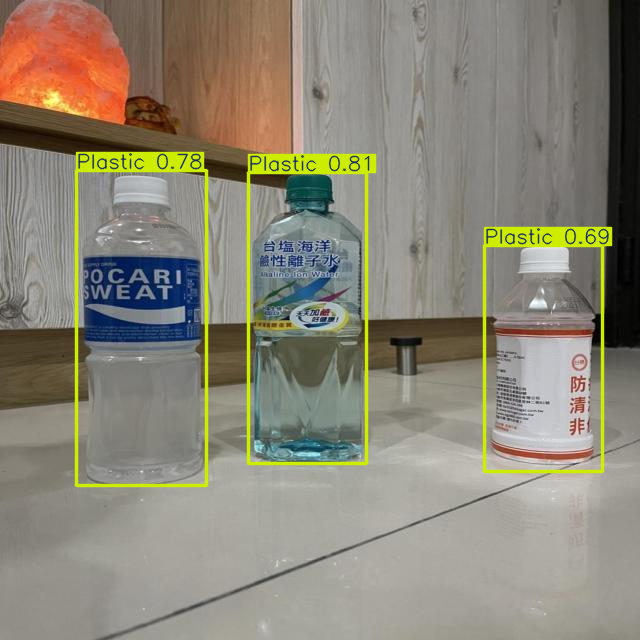

Ảnh kết quả được lưu trong: /content/runs/detect/predict
Số đối tượng phát hiện: 3
Class: Plastic | Confidence: 0.814
Class: Plastic | Confidence: 0.783
Class: Plastic | Confidence: 0.688


In [23]:
# ===== BƯỚC 12: thử mô hình với một ảnh bất kỳ =====
from google.colab import files           # để upload ảnh từ máy lên Colab
from IPython.display import display      # để hiển thị ảnh ngay trong notebook
from PIL import Image                    # thư viện xử lý ảnh

# Hiện nút "Choose Files": bấm vào và chọn ảnh rác trong máy của bạn.
uploaded_images = files.upload()
if not uploaded_images:
    raise RuntimeError("Bạn chưa upload ảnh.")

# Lấy tên file ảnh đầu tiên vừa upload.
test_image = next(iter(uploaded_images.keys()))

# Cho mô hình dự đoán trên ảnh đó.
predictions = best_model.predict(
    source=test_image,       # ảnh cần dự đoán
    conf=0.25,               # chỉ giữ các khung có độ tin cậy từ 25% trở lên
    imgsz=IMAGE_SIZE,
    save=True                # lưu ảnh kết quả (đã vẽ khung) vào thư mục runs/detect/predict
)

# Vẽ khung và tên loại rác lên ảnh rồi hiển thị.
# [..., ::-1] đổi thứ tự màu BGR (của OpenCV) sang RGB để màu hiển thị đúng.
annotated = predictions[0].plot()
display(Image.fromarray(annotated[..., ::-1]))

print("Ảnh kết quả được lưu trong:", predictions[0].save_dir)
result = predictions[0]

# Số vật thể máy tìm thấy trong ảnh.
print("Số đối tượng phát hiện:", len(result.boxes))

# In từng vật: loại rác và độ tin cậy (từ 0 đến 1).
for box in result.boxes:
    class_id = int(box.cls[0])           # số thứ tự của loại rác (0..8)
    confidence = float(box.conf[0])      # độ tin cậy của khung này

    print(
        "Class:", best_model.names[class_id],        # đổi số thứ tự thành tên loại rác
        "| Confidence:", round(confidence, 3)
    )

In [24]:
# ===== CUỐI CÙNG: lưu kết quả trước khi tắt Colab (tắt là MẤT HẾT nếu chưa lưu) =====

# 1) Xem tên các thư mục kết quả (val, val-2, predict...)
!ls /content/runs/detect

# 2) Gom mọi thứ cần giữ vào một thư mục
import shutil
from google.colab import files, drive

SAVE = "/content/RAC_results"
!rm -rf {SAVE}
!mkdir -p {SAVE}
!cp -r /content/waste_yolo_runs/yolov8n_waste_corrected {SAVE}/train_run
!cp -r /content/runs/detect {SAVE}/eval_and_predict

# 3) Lưu vào Google Drive (an toàn nhất)
drive.mount('/content/drive')
!cp -r {SAVE} /content/drive/MyDrive/

# 4) Nén thành file ZIP và tải về máy
shutil.make_archive("/content/RAC_results", "zip", SAVE)
files.download("/content/RAC_results.zip")

predict  val  val-2
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>